# Kia Theft Analysis

This notebook examines when and where Kia and Hyundai thefts became a serious problem. The audience is vehicle owners and members of the general public who are unfamiliar with the datasets. Therefore, the code is separated into small steps, technical language is limited, and every visual has a direct title and plain-English explanation.

Purpose and call to action:Help vehicle owners understand the scale of the problem and encourage them to contact their dealership about available anti-theft options, use a visible physical deterrent, and promptly report suspicious activity. City leaders and law-enforcement agencies should use local trends to target prevention resources and public education.

Medium: An R notebook that documents the analysis and displays six visuals. The visuals can later be copied into a PowerPoint, infographic, or public-information webpage.

### Four required datasets

1. KiaHyundaiMilwaukeeData.csv
2. kiaHyundaiThefts.csv
3. carTheftsMap.csv
4. Motherboard VICE News Kia Hyundai Theft Data.xlsx

In [1]:
install.packages("tidyverse", repos = "https://cloud.r-project.org")

Installing package into 'C:/Users/vinay/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)



package 'tidyverse' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\vinay\AppData\Local\Temp\Rtmpi4Hpuu\downloaded_packages


In [43]:
# Load the R packages
```{r setup, message=FALSE, warning=FALSE}
library(tidyverse)
library(readxl)
library(janitor)
library(treemapify)
library(scales)
```

ERROR: Error in parse(text = input): attempt to use zero-length variable name


### Load Data

In [44]:
milwaukee_raw <- read_csv(
  "KiaHyundaiMilwaukeeData.csv",
  na = c("", "-", "N/A"),
  show_col_types = FALSE
)

thefts_raw <- read_csv(
  "kiaHyundaiThefts.csv",
  na = c("", "-", "N/A"),
  show_col_types = FALSE
)

car_map_raw <- read_csv(
  "carTheftsMap.csv",
  na = c("", "-", "N/A"),
  show_col_types = FALSE
)

vice_raw <- suppressMessages(
  read_excel(
    "MotherboardVICENewsKiaHyundaiTheftData.xlsx",
    col_names = FALSE,
    na = c("", "-", "N/A")
  )
)

In [45]:
dim(milwaukee_raw)
dim(thefts_raw)
dim(car_map_raw)
dim(vice_raw)

[1] 48  7

[1] 552   7

[1] 556   9

[1]  47 211

In [46]:
head(milwaukee_raw)

month,year,city,state,countKiaHyundaiThefts,countOtherThefts,percentKiaHyundai
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Jan,2019,Milwaukee,WI,22,235,0.086
Feb,2019,Milwaukee,WI,13,218,0.056
Mar,2019,Milwaukee,WI,10,195,0.049
Apr,2019,Milwaukee,WI,10,238,0.040
May,2019,Milwaukee,WI,11,280,0.038
Jun,2019,Milwaukee,WI,15,330,0.043


In [47]:
head(thefts_raw)

month,year,city,state,countKiaHyundaiThefts,countOtherThefts,percentKiaHyundai
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Jan,2019,Atlanta,GA,17,264,0.060
Feb,2019,Atlanta,GA,11,205,0.051
Mar,2019,Atlanta,GA,18,181,0.090
Apr,2019,Atlanta,GA,15,223,0.063
May,2019,Atlanta,GA,16,277,0.055
Jun,2019,Atlanta,GA,14,220,0.060


In [48]:
head(car_map_raw)

agency_ori,geo_name,countCarThefts2019,countCarThefts2020,countCarThefts2021,countCarThefts2022,latitude,longitude,percentChange2019to2022
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MO0490300,Carthage PD,62,58,47,26,37.17585,-94.31335,-0.5806452
NA,Warren County SO,112,94,76,58,41.30879,-80.84788,-0.4821429
TX06802,Odessa PD,499,464,375,288,31.88933,-102.32989,-0.4228457
MO0530000,Laclede County SO,55,74,54,32,37.66346,-92.54901,-0.4181818
MO0480000,Jackson County SO,125,141,81,75,37.38440,-89.66792,-0.4000000
MN0070100,Mankato Dept of Public Safety,72,62,66,44,44.16168,-94.00876,-0.3888889


In [49]:
head(vice_raw)

...1,...2,...3,...4,...5,...6,...7,...8,...9,...10,⋯,...202,...203,...204,...205,...206,...207,...208,...209,...210,...211
<dttm>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
NA,Denver,NA,NA,El Paso,NA,NA,Portland,NA,NA,⋯,NA,"Peoria, AZ",NA,NA,"Houston, TX",NA,NA,"Prince George's County, MD",NA,NA
NA,Kia/Hyundais,All,Percent,Kia/Hyundais,All,Percent,Kia/Hyundais,All,Percent,⋯,Percent,Kia/Hyundais,All,Percent,Kia/Hyundais,All,Percent,Kia/Hyundais,All,Percent
2019-12-01,48.0,615.0,0.07804878049,13.0,103.0,0.1262135922,13.0,592.0,0.02195945946,⋯,0.05555555556,2.0,27.0,0.07407407407,24.0,603.0,NA,11.0,210.0,0.05238095238
2020-01-01,21.0,519.0,0.04046242775,9.0,95.0,0.09473684211,12.0,559.0,0.02146690519,⋯,0.09803921569,1.0,17.0,0.05882352941,18.0,586.0,NA,10.0,215.0,0.04651162791
2020-02-01,28.0,402.0,0.06965174129,5.0,64.0,0.078125,10.0,498.0,0.02008032129,⋯,0.15,2.0,19.0,0.1052631579,15.0,556.0,NA,6.0,169.0,0.03550295858
2020-03-01,35.0,508.0,0.0688976378,6.0,75.0,0.08,4.0,465.0,0.008602150538,⋯,0.03571428571,2.0,17.0,0.1176470588,26.0,524.0,NA,7.0,167.0,0.04191616766


### Data cleaning and formatting

Only transformations needed for grouping, calculations, dates, or visuals are performed.

- Clean column names:Converts names such as `countKiaHyundaiThefts` to `count_kia_hyundai_thefts`. This makes code easier to read and prevents typing errors.
- Rename columns:Gives important fields shorter, consistent names such as `kia_hyundai_thefts`.
- trim text: Removes invisible spaces only from fields used for grouping and filtering. Without trimming, `Milwaukee` and `Milwaukee ` could become separate categories.
- Standardize capitalization: Makes city and state labels display consistently.
- Convert to numbers: Theft values must be numeric before totals and percentages can be calculated.
- Create a date: Month and year are combined so observations appear in the correct time order.
- Keep missing data missing: No theft count is estimated or replaced with zero.

### 5. Clean the Milwaukee dataset



In [50]:
#Clean and rename column names:=This is required because the
#original names use mixed capitalization and are harder to type consistently.

milwaukee <- milwaukee_raw %>%
  clean_names() %>%
  rename(
    kia_hyundai_thefts = count_kia_hyundai_thefts,
    other_thefts = count_other_thefts,
    reported_share = percent_kia_hyundai
  )

names(milwaukee)

[1] "month"              "year"               "city"              
[4] "state"              "kia_hyundai_thefts" "other_thefts"      
[7] "reported_share"

In [51]:
#Trim and standardize text-This is performed only on `month`, `city`, and `state` because 
#those fields are used for dates, filters, labels, and grouping.

milwaukee <- milwaukee %>%
  mutate(
    month = str_to_title(str_trim(month)),
    city = str_to_title(str_trim(city)),
    state = str_to_upper(str_trim(state))
  )

head(milwaukee)

month,year,city,state,kia_hyundai_thefts,other_thefts,reported_share
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Jan,2019,Milwaukee,WI,22,235,0.086
Feb,2019,Milwaukee,WI,13,218,0.056
Mar,2019,Milwaukee,WI,10,195,0.049
Apr,2019,Milwaukee,WI,10,238,0.040
May,2019,Milwaukee,WI,11,280,0.038
Jun,2019,Milwaukee,WI,15,330,0.043


In [52]:
#Convert values and create analytical fields-The theft counts must be numeric for addition. 
#A real date is needed for a time chart. `calculated_share` is created from the counts and is 
#calculated only when `total_thefts` is greater than zero.

milwaukee <- milwaukee %>%
  mutate(
    year = as.integer(year),
    kia_hyundai_thefts = as.numeric(kia_hyundai_thefts),
    other_thefts = as.numeric(other_thefts),
    reported_share = as.numeric(reported_share),
    date = as.Date(paste(year, month, 1), format = "%Y %b %d"),
    total_thefts = kia_hyundai_thefts + other_thefts,
    calculated_share = if_else(
      total_thefts > 0,
      kia_hyundai_thefts / total_thefts,
      NA_real_
    )
  )

head(milwaukee)

month,year,city,state,kia_hyundai_thefts,other_thefts,reported_share,date,total_thefts,calculated_share
<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<date>,<dbl>,<dbl>
Jan,2019,Milwaukee,WI,22,235,0.086,2019-01-01,257,0.08560311
Feb,2019,Milwaukee,WI,13,218,0.056,2019-02-01,231,0.05627706
Mar,2019,Milwaukee,WI,10,195,0.049,2019-03-01,205,0.04878049
Apr,2019,Milwaukee,WI,10,238,0.040,2019-04-01,248,0.04032258
May,2019,Milwaukee,WI,11,280,0.038,2019-05-01,291,0.03780069
Jun,2019,Milwaukee,WI,15,330,0.043,2019-06-01,345,0.04347826


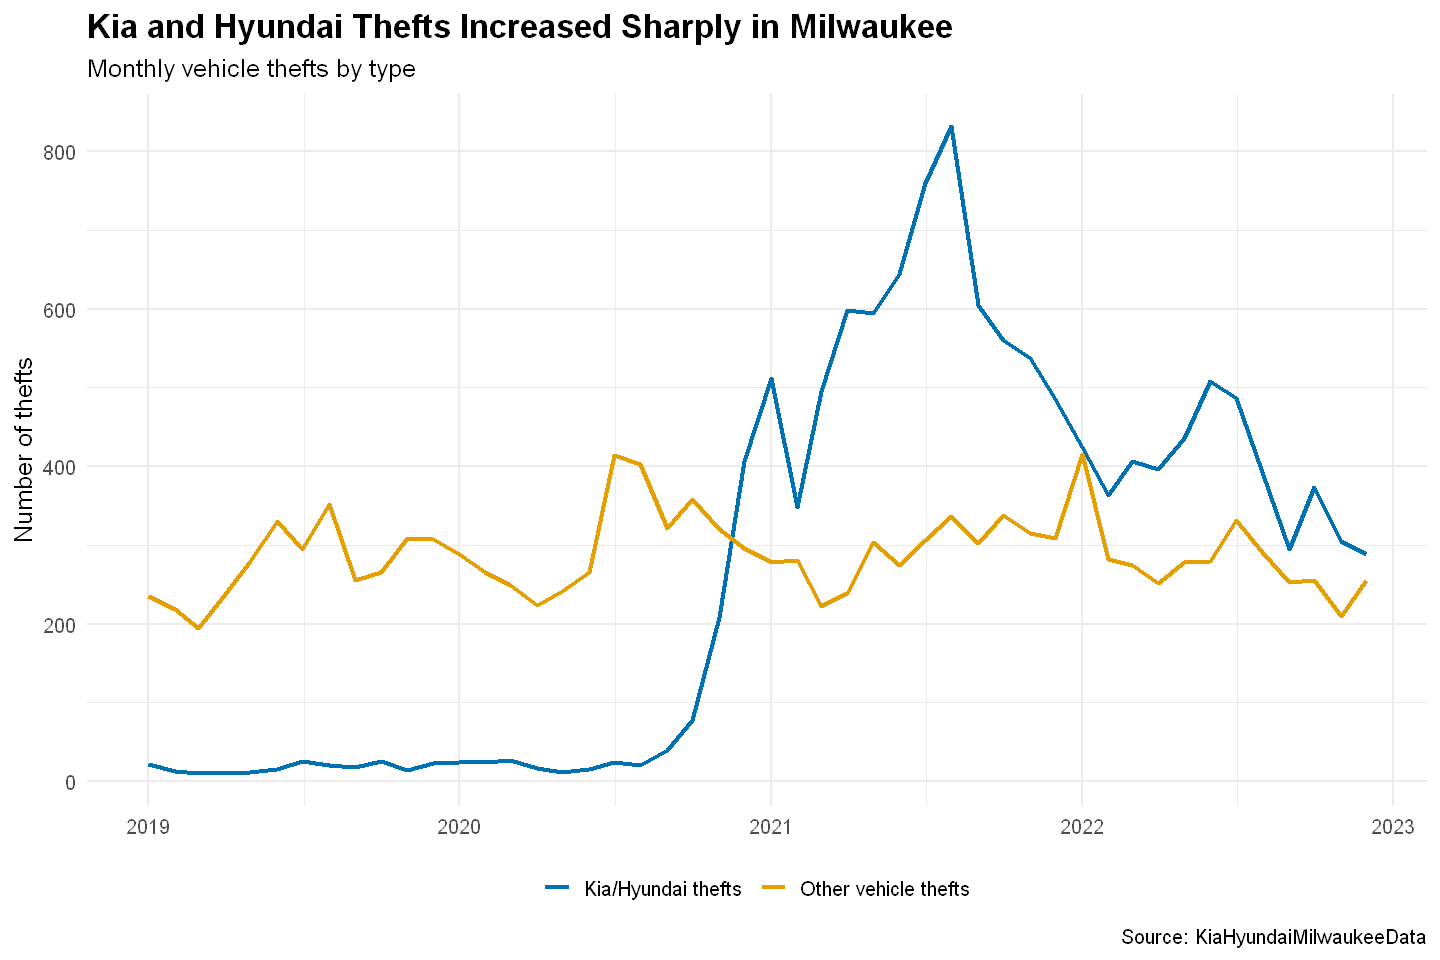

In [53]:
milwaukee_plot <- milwaukee %>%
  select(
    date,
    kia_hyundai_thefts,
    other_thefts
  ) %>%
  filter(!is.na(date)) %>%
  pivot_longer(
    cols = c(kia_hyundai_thefts, other_thefts),
    names_to = "theft_type",
    values_to = "thefts"
  ) %>%
  filter(!is.na(thefts)) %>%
  mutate(
    theft_type = recode(
      theft_type,
      kia_hyundai_thefts = "Kia/Hyundai thefts",
      other_thefts = "Other vehicle thefts"
    )
  )

ggplot(
  milwaukee_plot,
  aes(
    x = date,
    y = thefts,
    color = theft_type
  )
) +
  geom_line(linewidth = 1.2) +
  scale_color_manual(
    values = c(
      "Kia/Hyundai thefts" = "#0072B2",
      "Other vehicle thefts" = "#E69F00"
    )
  ) +
  labs(
    title = "Kia and Hyundai Thefts Increased Sharply in Milwaukee",
    subtitle = "Monthly vehicle thefts by type",
    x = NULL,
    y = "Number of thefts",
    color = NULL,
    caption = "Source: KiaHyundaiMilwaukeeData"
  ) +
  theme_minimal(base_size = 15) +
  theme(
    plot.title = element_text(
      face = "bold",
      size = 20
    ),
    legend.position = "bottom"
  )

Kia and Hyundai thefts in Milwaukee were very low in 2019 and most of 2020 but increased sharply near the end of 2020. They peaked at more than 800 thefts in one month during 2021. Other vehicle thefts stayed more stable. This shows that Kia and Hyundai vehicles contributed greatly to the increase in Milwaukee vehicle thefts.

### Clean the general Kia/Hyundai theft dataset

In [54]:
thefts <- thefts_raw %>%
  clean_names() %>%
  rename(
    kia_hyundai_thefts = count_kia_hyundai_thefts,
    other_thefts = count_other_thefts,
    reported_share = percent_kia_hyundai
  )

names(thefts)

[1] "month"              "year"               "city"              
[4] "state"              "kia_hyundai_thefts" "other_thefts"      
[7] "reported_share"

In [55]:
thefts <- thefts %>%
  mutate(
    month = str_to_title(str_trim(month)),
    city = str_to_title(str_trim(city)),
    state = str_to_upper(str_trim(state)),
    year = as.integer(year),
    kia_hyundai_thefts = as.numeric(kia_hyundai_thefts),
    other_thefts = as.numeric(other_thefts),
    reported_share = as.numeric(reported_share),
    date = as.Date(paste(year, month, 1), format = "%Y %b %d"),
    total_thefts = kia_hyundai_thefts + other_thefts,
    calculated_share = if_else(
      total_thefts > 0,
      kia_hyundai_thefts / total_thefts,
      NA_real_
    )
  )

head(thefts)

month,year,city,state,kia_hyundai_thefts,other_thefts,reported_share,date,total_thefts,calculated_share
<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<date>,<dbl>,<dbl>
Jan,2019,Atlanta,GA,17,264,0.060,2019-01-01,281,0.06049822
Feb,2019,Atlanta,GA,11,205,0.051,2019-02-01,216,0.05092593
Mar,2019,Atlanta,GA,18,181,0.090,2019-03-01,199,0.09045226
Apr,2019,Atlanta,GA,15,223,0.063,2019-04-01,238,0.06302521
May,2019,Atlanta,GA,16,277,0.055,2019-05-01,293,0.05460751
Jun,2019,Atlanta,GA,14,220,0.060,2019-06-01,234,0.05982906


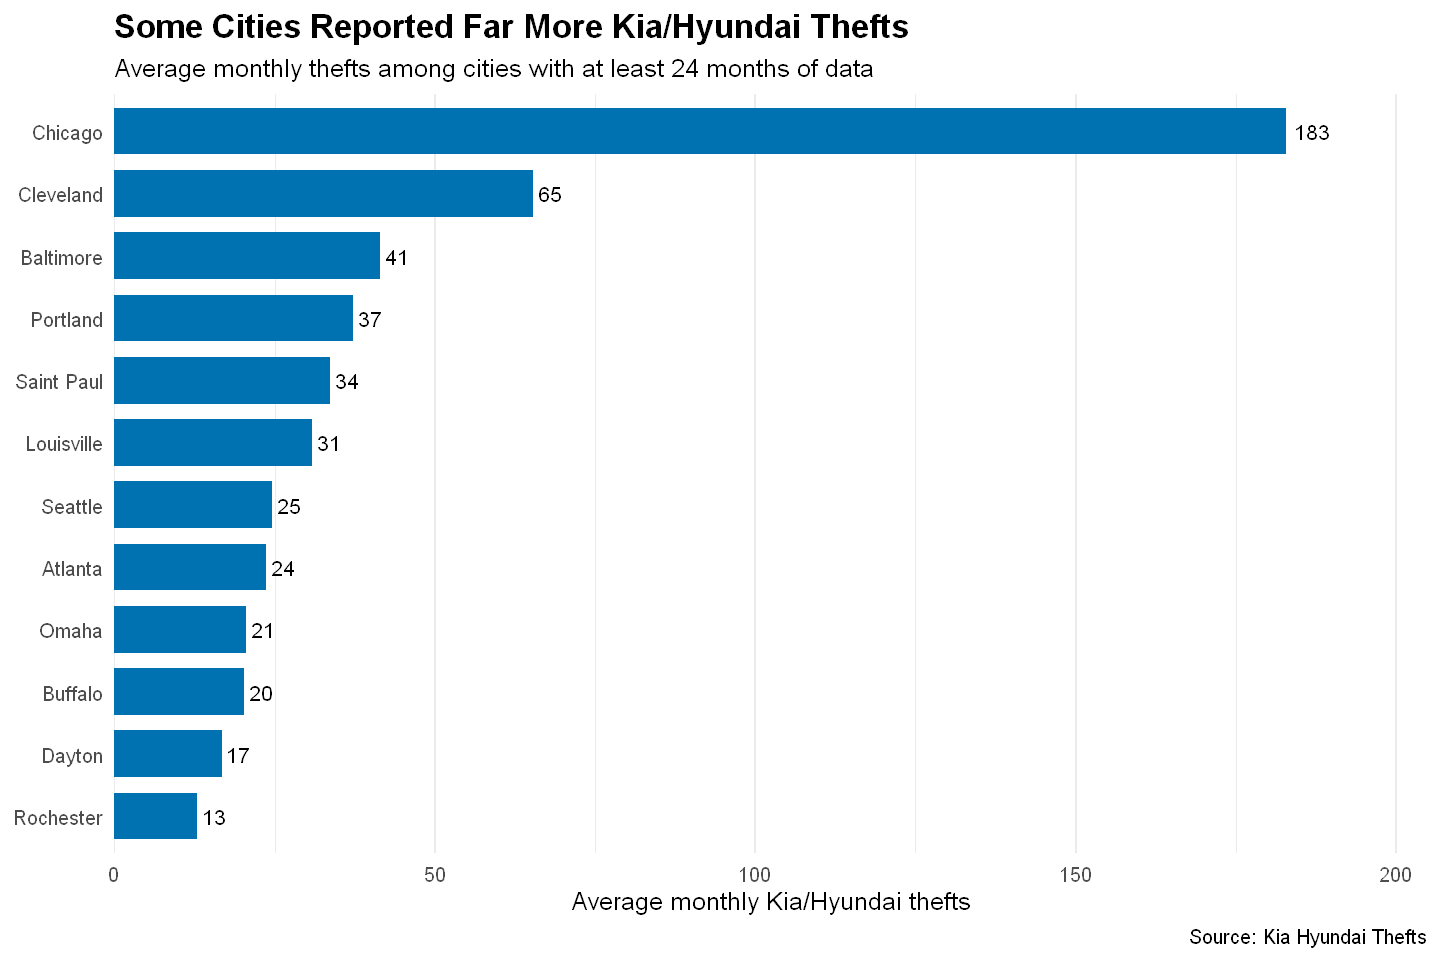

In [56]:
city_summary <- thefts %>%
  group_by(city) %>%
  summarise(
    months_reported = sum(!is.na(kia_hyundai_thefts)),
    average_monthly_thefts = mean(
      kia_hyundai_thefts,
      na.rm = TRUE
    ),
    .groups = "drop"
  ) %>%
  filter(
    months_reported >= 24,
    is.finite(average_monthly_thefts)
  ) %>%
  slice_max(
    order_by = average_monthly_thefts,
    n = 12,
    with_ties = FALSE
  ) %>%
  mutate(
    city = forcats::fct_reorder(
      city,
      average_monthly_thefts
    )
  )

ggplot(
  city_summary,
  aes(
    x = average_monthly_thefts,
    y = city
  )
) +
  geom_col(
    fill = "#0072B2",
    width = 0.75
  ) +
  geom_text(
    aes(label = round(average_monthly_thefts)),
    hjust = -0.2,
    size = 4.5
  ) +
  scale_x_continuous(
    expand = expansion(mult = c(0, 0.12))
  ) +
  labs(
    title = "Some Cities Reported Far More Kia/Hyundai Thefts",
    subtitle = "Average monthly thefts among cities with at least 24 months of data",
    x = "Average monthly Kia/Hyundai thefts",
    y = NULL,
    caption = "Source: Kia Hyundai Thefts"
  ) +
  theme_minimal(base_size = 15) +
  theme(
    plot.title = element_text(
      face = "bold",
      size = 20
    ),
    panel.grid.major.y = element_blank()
  )

Chicago reported the highest average monthly Kia and Hyundai thefts at about 183, far more than any other city. Cleveland ranked second with 65, followed by Baltimore with 41 and Portland with 37. This shows that Kia and Hyundai thefts were much more severe in some cities than others. Only cities with at least 24 months of data were included.

### Clean the car-theft map dataset

In [57]:
car_map <- car_map_raw %>%
  clean_names() %>%
  rename(
    agency_name = geo_name,
    thefts_2019 = count_car_thefts2019,
    thefts_2022 = count_car_thefts2022
  ) %>%
  mutate(
    agency_name = str_trim(agency_name),
    thefts_2019 = as.numeric(thefts_2019),
    thefts_2022 = as.numeric(thefts_2022)
  )

head(car_map)

agency_ori,agency_name,thefts_2019,count_car_thefts2020,count_car_thefts2021,thefts_2022,latitude,longitude,percent_change2019to2022
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MO0490300,Carthage PD,62,58,47,26,37.17585,-94.31335,-0.5806452
NA,Warren County SO,112,94,76,58,41.30879,-80.84788,-0.4821429
TX06802,Odessa PD,499,464,375,288,31.88933,-102.32989,-0.4228457
MO0530000,Laclede County SO,55,74,54,32,37.66346,-92.54901,-0.4181818
MO0480000,Jackson County SO,125,141,81,75,37.38440,-89.66792,-0.4000000
MN0070100,Mankato Dept of Public Safety,72,62,66,44,44.16168,-94.00876,-0.3888889


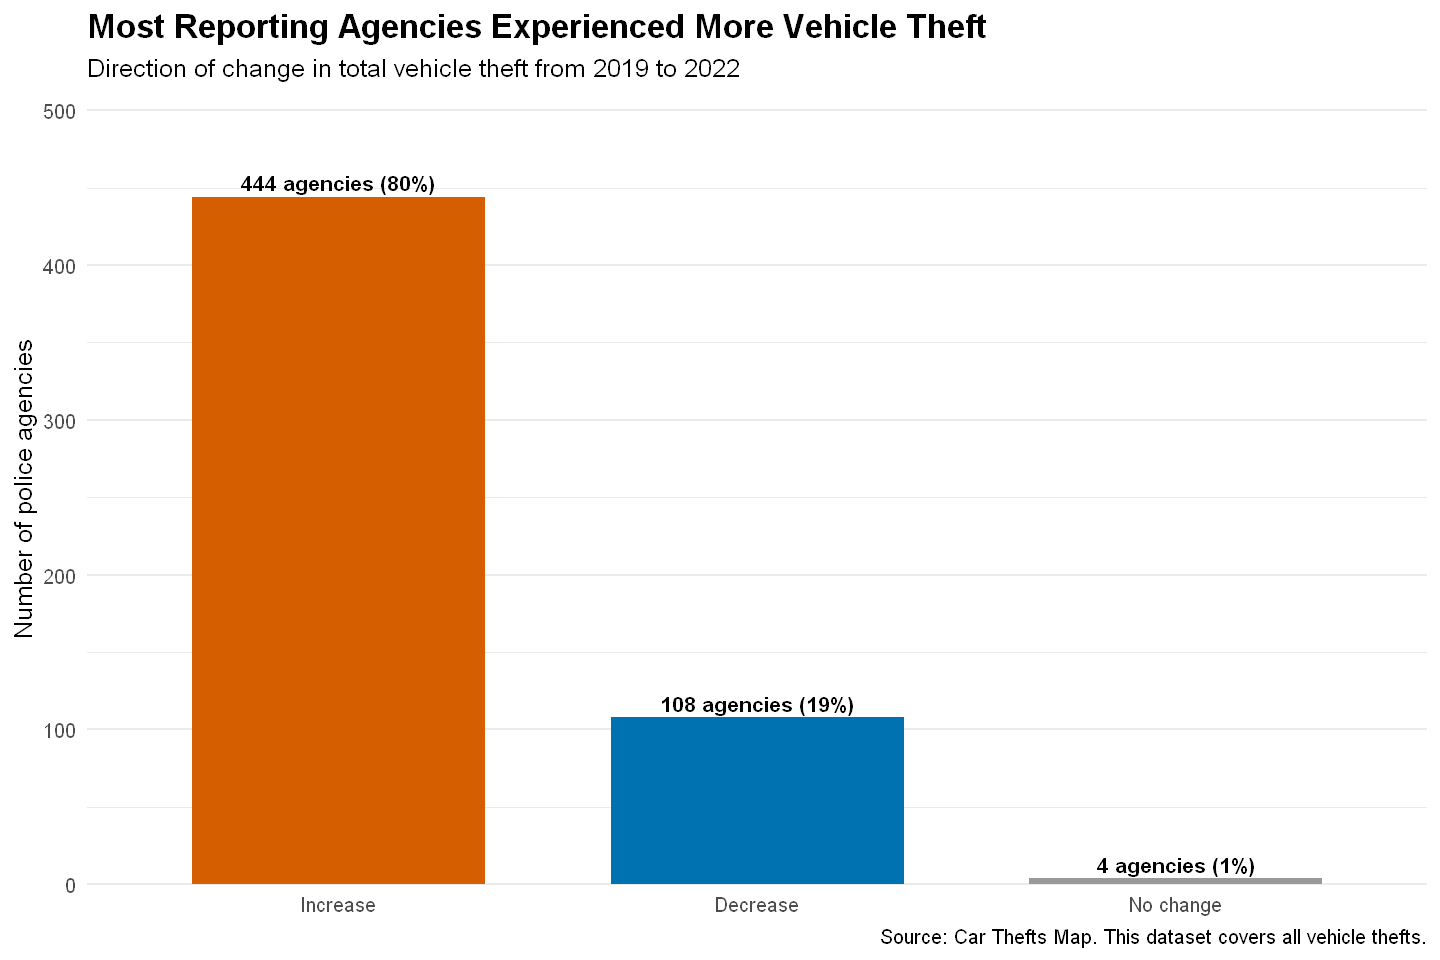

In [58]:
agency_change <- car_map %>%
  filter(
    !is.na(thefts_2019),
    !is.na(thefts_2022)
  ) %>%
  mutate(
    change_direction = case_when(
      thefts_2022 > thefts_2019 ~ "Increase",
      thefts_2022 < thefts_2019 ~ "Decrease",
      TRUE ~ "No change"
    )
  ) %>%
  count(change_direction) %>%
  mutate(
    change_direction = factor(
      change_direction,
      levels = c("Increase", "Decrease", "No change")
    ),
    share = n / sum(n),
    label = paste0(
      n,
      " agencies (",
      scales::percent(share, accuracy = 1),
      ")"
    )
  )

ggplot(
  agency_change,
  aes(
    x = change_direction,
    y = n,
    fill = change_direction
  )
) +
  geom_col(width = 0.7) +
  geom_text(
    aes(label = label),
    vjust = -0.4,
    size = 4.5,
    fontface = "bold"
  ) +
  scale_fill_manual(
    values = c(
      "Increase" = "#D55E00",
      "Decrease" = "#0072B2",
      "No change" = "#999999"
    )
  ) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Most Reporting Agencies Experienced More Vehicle Theft",
    subtitle = "Direction of change in total vehicle theft from 2019 to 2022",
    x = NULL,
    y = "Number of police agencies",
    caption = paste(
      "Source: Car Thefts Map.",
      "This dataset covers all vehicle thefts."
    )
  ) +
  theme_minimal(base_size = 15) +
  theme(
    plot.title = element_text(
      face = "bold",
      size = 20
    ),
    legend.position = "none",
    panel.grid.major.x = element_blank()
  )

Most police agencies reported an increase in total vehicle theft from 2019 to 2022. About 80% of agencies reported an increase, while 19% reported a decrease and only 1% reported no change. This shows that rising vehicle theft was a widespread problem, not limited to only a few locations. This dataset includes all vehicle thefts, not only Kia and Hyundai vehicles.

### Reshape and clean the Motherboard/VICE spreadsheet
he VICE file is the only dataset that requires a larger formatting change. Its cities are in the first row, measures are in the second row, and each city occupies three columns. The data must be reshaped into one row per city and month before it can be summarized.

In [59]:
city_header <- tibble(
  city = as.character(unlist(vice_raw[1, -1]))
) %>%
  fill(city)

measure_header <- as.character(unlist(vice_raw[2, -1]))

head(city_header, 9)
head(measure_header, 9)

city
<chr>
Denver
Denver
Denver
El Paso
El Paso
El Paso
Portland
Portland
Portland


[1] "Kia/Hyundais" "All"          "Percent"      "Kia/Hyundais" "All"         
[6] "Percent"      "Kia/Hyundais" "All"          "Percent"

### Create simple names for the VICE columns


In [60]:
#City names are changed to lowercase with underscores because they will temporarily become part of the column names. T
#The three measure labels are renamed to clear analytical names

city_names <- city_header$city %>%
  str_trim() %>%
  str_to_lower() %>%
  str_replace_all("[^a-z0-9]+", "_") %>%
  str_remove("^_") %>%
  str_remove("_$")

measure_names <- case_when(
  str_detect(str_to_lower(measure_header), "kia") ~ "kia_hyundai_thefts",
  str_detect(str_to_lower(measure_header), "percent") ~ "reported_share",
  TRUE ~ "total_thefts"
)

new_names <- c(
  "date",
  paste(city_names, measure_names, sep = "__")
)

head(new_names, 10)

[1] "date"                         "denver__kia_hyundai_thefts"  
 [3] "denver__total_thefts"         "denver__reported_share"      
 [5] "el_paso__kia_hyundai_thefts"  "el_paso__total_thefts"       
 [7] "el_paso__reported_share"      "portland__kia_hyundai_thefts"
 [9] "portland__total_thefts"       "portland__reported_share"

In [61]:
#Apply the new names and remove the two header rows
vice <- vice_raw
names(vice) <- new_names
vice <- vice[-c(1, 2), ]

head(vice)

date,denver__kia_hyundai_thefts,denver__total_thefts,denver__reported_share,el_paso__kia_hyundai_thefts,el_paso__total_thefts,el_paso__reported_share,portland__kia_hyundai_thefts,portland__total_thefts,portland__reported_share,⋯,syracuse_ny__reported_share,peoria_az__kia_hyundai_thefts,peoria_az__total_thefts,peoria_az__reported_share,houston_tx__kia_hyundai_thefts,houston_tx__total_thefts,houston_tx__reported_share,prince_george_s_county_md__kia_hyundai_thefts,prince_george_s_county_md__total_thefts,prince_george_s_county_md__reported_share
<dttm>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2019-12-01,48.0,615.0,0.07804878049,13.0,103.0,0.1262135922,13.0,592.0,0.02195945946,⋯,0.05555555556,2.0,27.0,0.07407407407,24.0,603.0,NA,11.0,210.0,0.05238095238
2020-01-01,21.0,519.0,0.04046242775,9.0,95.0,0.09473684211,12.0,559.0,0.02146690519,⋯,0.09803921569,1.0,17.0,0.05882352941,18.0,586.0,NA,10.0,215.0,0.04651162791
2020-02-01,28.0,402.0,0.06965174129,5.0,64.0,0.078125,10.0,498.0,0.02008032129,⋯,0.15,2.0,19.0,0.1052631579,15.0,556.0,NA,6.0,169.0,0.03550295858
2020-03-01,35.0,508.0,0.0688976378,6.0,75.0,0.08,4.0,465.0,0.008602150538,⋯,0.03571428571,2.0,17.0,0.1176470588,26.0,524.0,NA,7.0,167.0,0.04191616766
2020-04-01,39.0,616.0,0.06331168831,1.0,57.0,0.01754385965,7.0,488.0,0.0143442623,⋯,0.03571428571,3.0,13.0,0.2307692308,21.0,541.0,NA,7.0,163.0,0.04294478528
2020-05-01,37.0,692.0,0.05346820809,1.0,62.0,0.01612903226,7.0,387.0,0.0180878553,⋯,0.06060606061,0.0,9.0,0,27.0,633.0,NA,6.0,173.0,0.03468208092


In [62]:
##Convert the spreadsheet from wide to long format

vice_long <- vice %>%
  pivot_longer(
    cols = -date,
    names_to = c("city", "measure"),
    names_sep = "__",
    values_to = "value"
  )

head(vice_long)

date,city,measure,value
<dttm>,<chr>,<chr>,<chr>
2019-12-01,denver,kia_hyundai_thefts,48.0
2019-12-01,denver,total_thefts,615.0
2019-12-01,denver,reported_share,0.07804878049
2019-12-01,el_paso,kia_hyundai_thefts,13.0
2019-12-01,el_paso,total_thefts,103.0
2019-12-01,el_paso,reported_share,0.1262135922


In [63]:
#Convert values and place the measures into columns

vice_clean <- vice_long %>%
  mutate(
    date = as.Date(date),
    value = parse_number(as.character(value))
  ) %>%
  pivot_wider(
    names_from = measure,
    values_from = value
  ) %>%
  mutate(
    city = str_to_title(str_replace_all(city, "_", " ")),
    other_thefts = total_thefts - kia_hyundai_thefts,
    calculated_share = if_else(
      total_thefts > 0,
      kia_hyundai_thefts / total_thefts,
      NA_real_
    )
  )

head(vice_clean)

date,city,kia_hyundai_thefts,total_thefts,reported_share,other_thefts,calculated_share
<date>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2019-12-01,Denver,48,615,0.07804878,567,0.07804878
2019-12-01,El Paso,13,103,0.12621359,90,0.12621359
2019-12-01,Portland,13,592,0.02195946,579,0.02195946
2019-12-01,Atlanta,NA,NA,NA,NA,NA
2019-12-01,Chicago,46,767,0.05997392,721,0.05997392
2019-12-01,Virginia Beach,NA,NA,NA,NA,NA


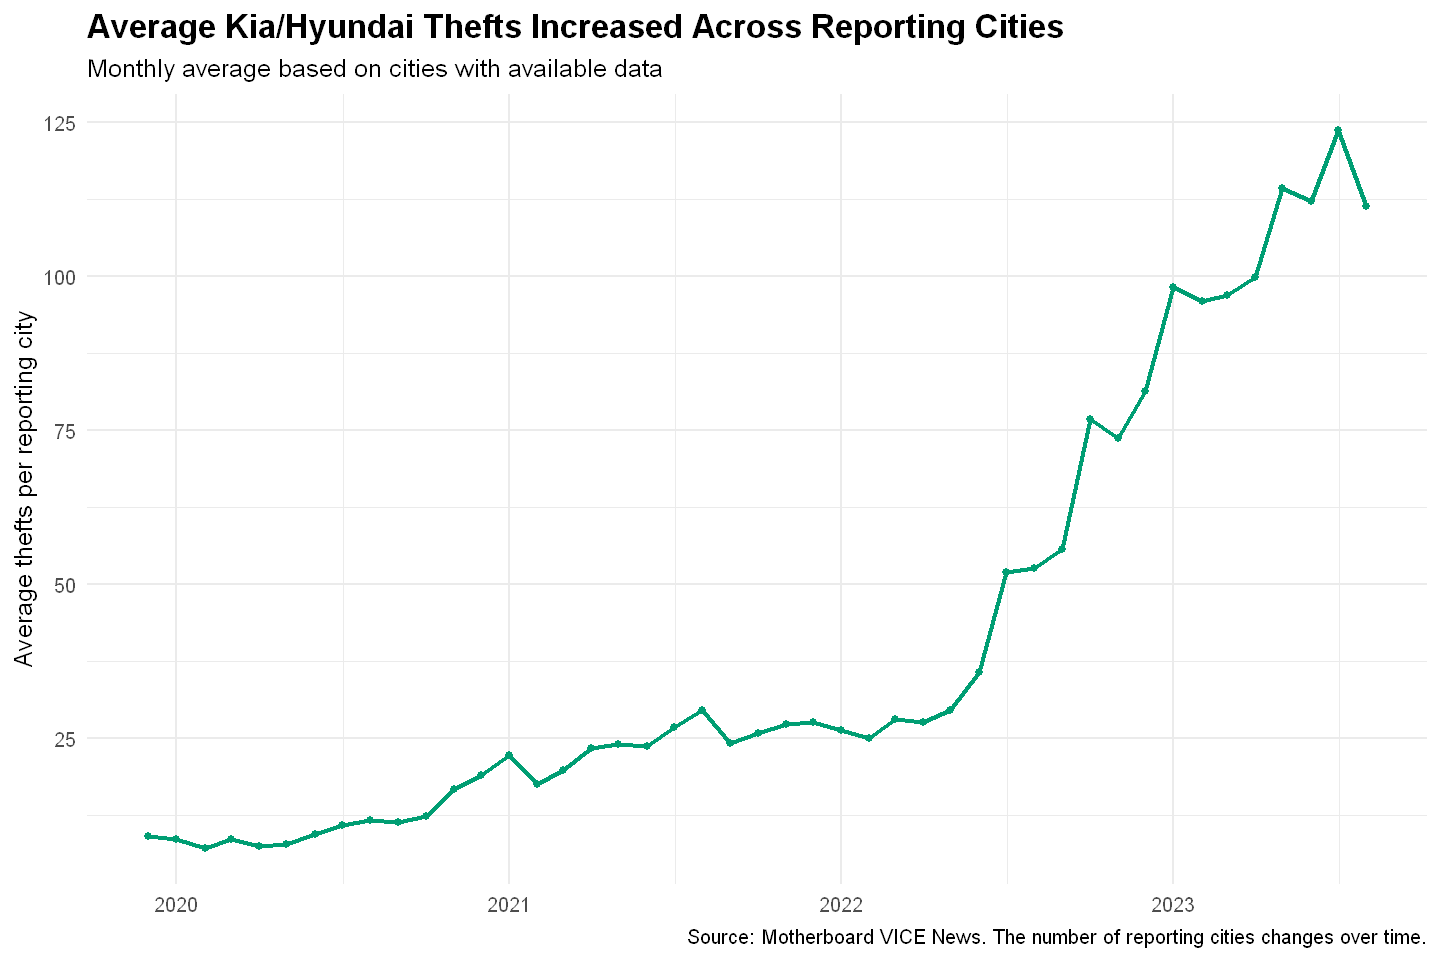

In [64]:
vice_monthly <- vice_clean %>%
  filter(
    !is.na(date),
    !is.na(kia_hyundai_thefts)
  ) %>%
  group_by(date) %>%
  summarise(
    average_monthly_thefts = mean(
      kia_hyundai_thefts,
      na.rm = TRUE
    ),
    cities_reporting = n_distinct(city),
    .groups = "drop"
  )

ggplot(
  vice_monthly,
  aes(
    x = date,
    y = average_monthly_thefts
  )
) +
  geom_line(
    color = "#009E73",
    linewidth = 1.3
  ) +
  geom_point(
    color = "#009E73",
    size = 2
  ) +
  labs(
    title = "Average Kia/Hyundai Thefts Increased Across Reporting Cities",
    subtitle = "Monthly average based on cities with available data",
    x = NULL,
    y = "Average thefts per reporting city",
    caption = paste(
      "Source: Motherboard VICE News.",
      "The number of reporting cities changes over time."
    )
  ) +
  theme_minimal(base_size = 15) +
  theme(
    plot.title = element_text(
      face = "bold",
      size = 20
    )
  )

Average Kia and Hyundai thefts increased steadily across reporting cities, with the sharpest growth beginning in 2022. The average rose from fewer than 10 thefts per city in 2020 to more than 100 in 2023. The number of cities reporting data changed over time, so the results should be interpreted carefully

### Data Checks

In [65]:
milwaukee_quality <- milwaukee %>%
  summarise(
    rows = n(),
    missing_dates = sum(is.na(date)),
    missing_kia_hyundai = sum(is.na(kia_hyundai_thefts)),
    missing_other = sum(is.na(other_thefts)),
    negative_counts = sum(
      kia_hyundai_thefts < 0 | other_thefts < 0,
      na.rm = TRUE
    ),
    duplicate_city_months = sum(duplicated(paste(city, date)))
  )

milwaukee_quality

rows,missing_dates,missing_kia_hyundai,missing_other,negative_counts,duplicate_city_months
<int>,<int>,<int>,<int>,<int>,<int>
48,0,0,0,0,0


In [ ]:
The Milwaukee dataset contains 48 records with no missing values, negative theft counts, or duplicate city-month records. Therefore, the data is ready for analysis.

thefts_quality <- thefts %>%
  summarise(
    rows = n(),
    cities = n_distinct(city),
    missing_dates = sum(is.na(date)),
    missing_kia_hyundai = sum(is.na(kia_hyundai_thefts)),
    missing_other = sum(is.na(other_thefts)),
    negative_counts = sum(
      kia_hyundai_thefts < 0 | other_thefts < 0,
      na.rm = TRUE
    ),
    duplicate_city_months = sum(duplicated(paste(city, date)))
  )

thefts_quality

In [67]:
vice_quality <- vice_clean %>%
  summarise(
    rows = n(),
    cities = n_distinct(city),
    missing_dates = sum(is.na(date)),
    missing_kia_hyundai = sum(is.na(kia_hyundai_thefts)),
    missing_totals = sum(is.na(total_thefts)),
    impossible_shares = sum(
      calculated_share < 0 | calculated_share > 1,
      na.rm = TRUE
    )
  )

vice_quality

rows,cities,missing_dates,missing_kia_hyundai,missing_totals,impossible_shares
<int>,<int>,<int>,<int>,<int>,<int>
3150,70,0,214,212,0


The Milwaukee, general Kia/Hyundai, and VICE datasets contain overlapping city-month observations. Combining them and then selecting a preferred source would require an assumption about which source is most accurate. It could also double-count thefts.

### Visual 1 — Stacked area chart

#### Milwaukee vehicle thefts over time

Why this visual supports the story-The stacked area chart shows both the total scale of vehicle theft and how much of the total came from Kia and Hyundai vehicles. The same category colors are used throughout the notebook to support Gestalt's similarity principle.

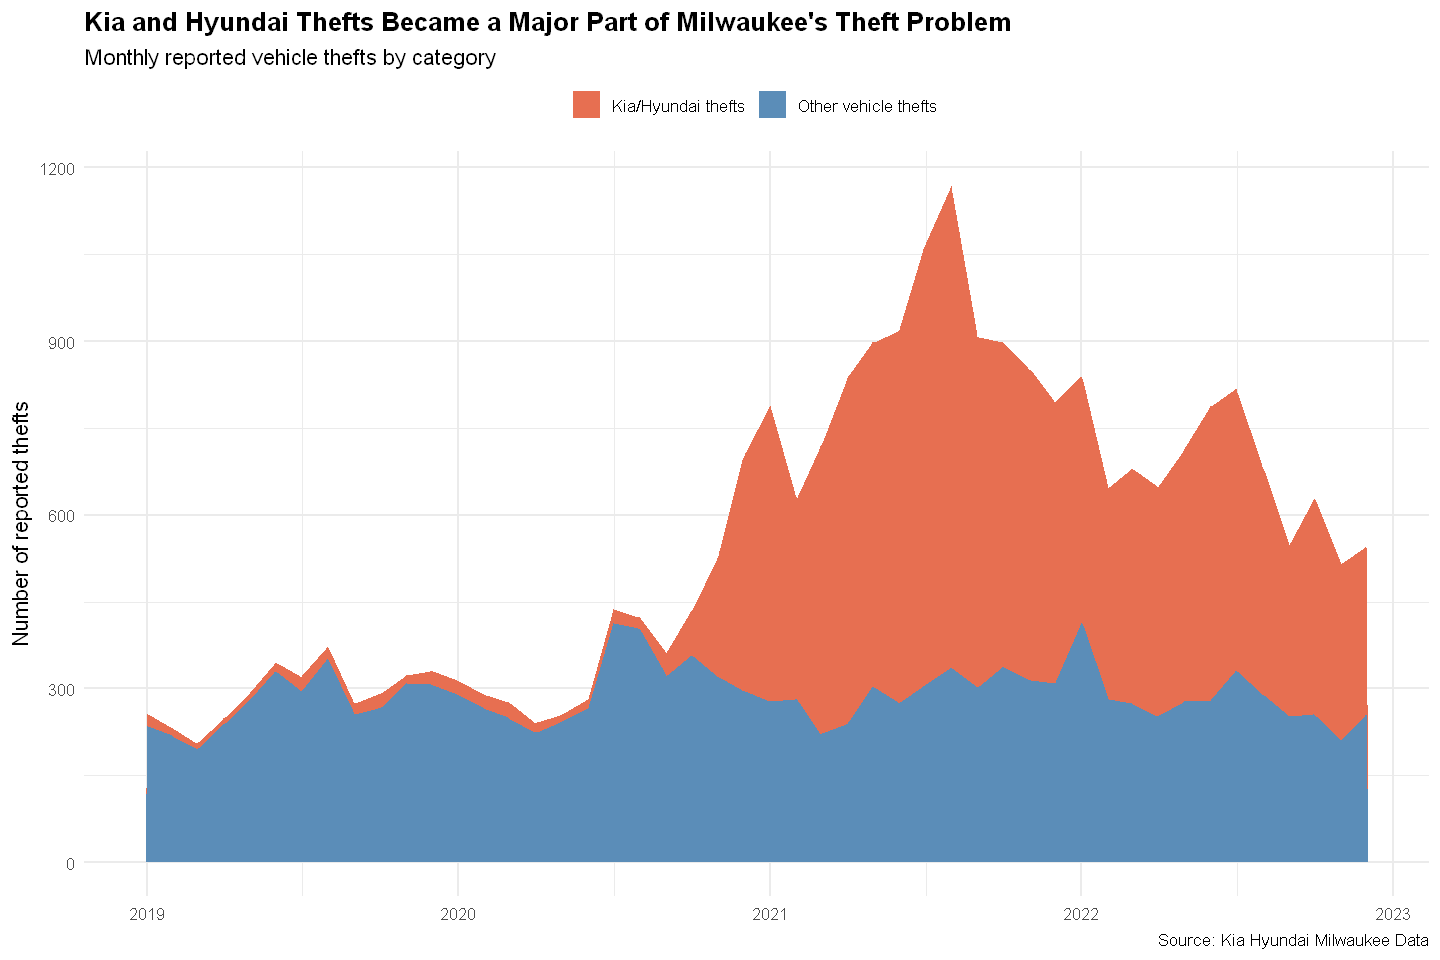

In [68]:
milwaukee_area <- milwaukee %>%
  select(date, kia_hyundai_thefts, other_thefts) %>%
  filter(
    !is.na(date),
    !is.na(kia_hyundai_thefts),
    !is.na(other_thefts)
  ) %>%
  pivot_longer(
    cols = c(kia_hyundai_thefts, other_thefts),
    names_to = "theft_type",
    values_to = "thefts"
  ) %>%
  mutate(
    theft_type = recode(
      theft_type,
      kia_hyundai_thefts = "Kia/Hyundai thefts",
      other_thefts = "Other vehicle thefts"
    )
  )

ggplot(
  milwaukee_area,
  aes(x = date, y = thefts, fill = theft_type)
) +
  geom_area() +
  scale_fill_manual(
    values = c(
      "Kia/Hyundai thefts" = "#E76F51",
      "Other vehicle thefts" = "#5B8DB8"
    )
  ) +
  labs(
    title = "Kia and Hyundai Thefts Became a Major Part of Milwaukee's Theft Problem",
    subtitle = "Monthly reported vehicle thefts by category",
    x = NULL,
    y = "Number of reported thefts",
    fill = NULL,
    caption = "Source: Kia Hyundai Milwaukee Data"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "top",
    plot.title = element_text(face = "bold")
  )

### Visual 2 — Stacked bar chart

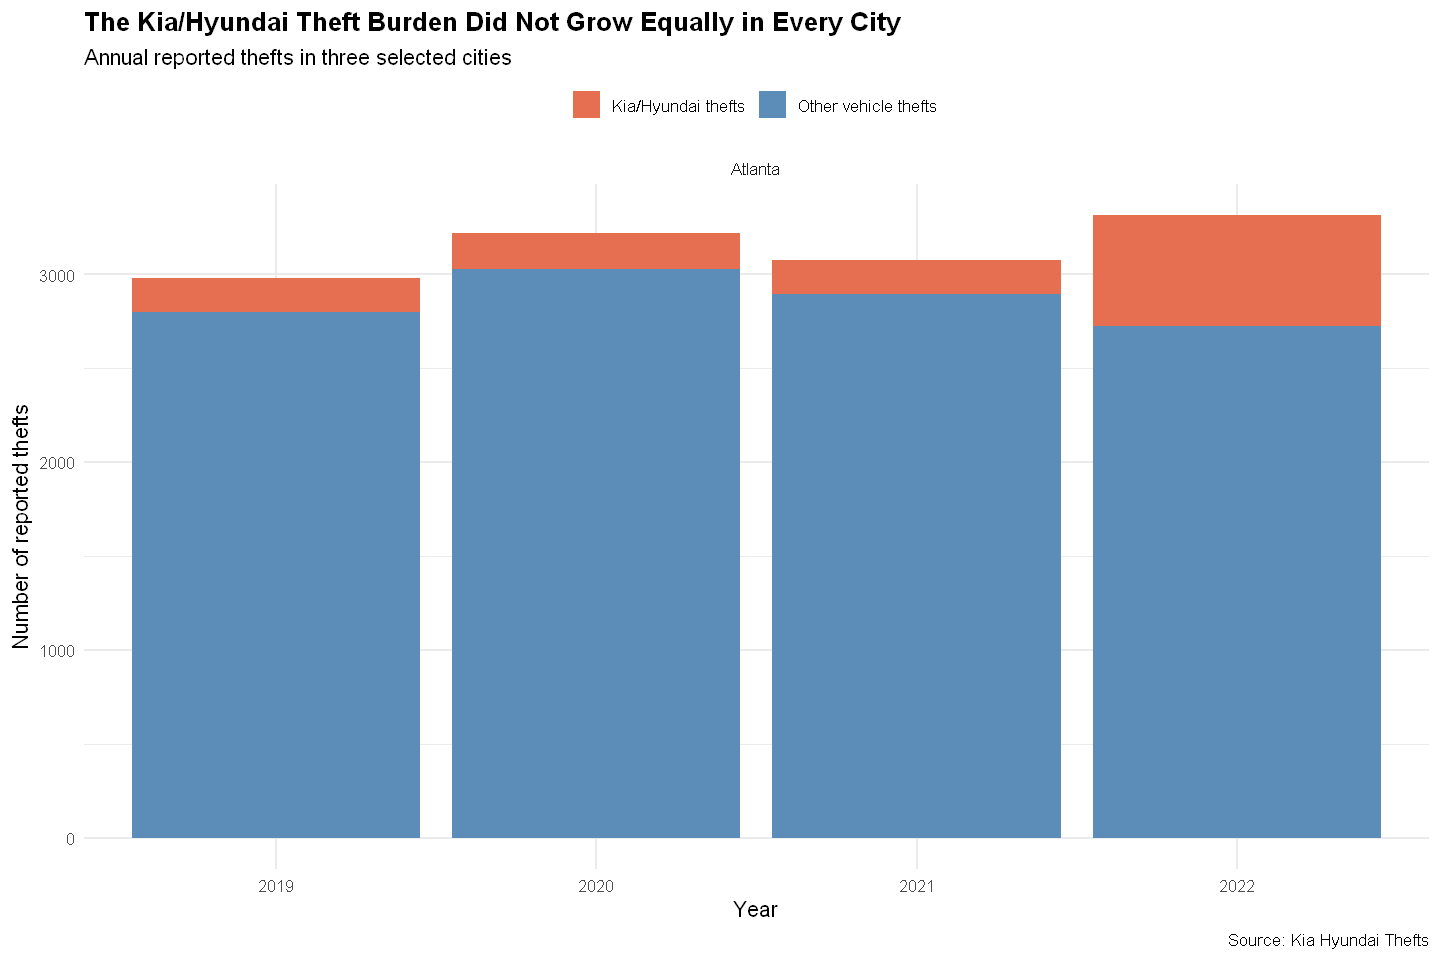

In [69]:
selected_cities <- c("Atlanta", "Denver", "Milwaukee")

yearly_selected <- thefts %>%
  filter(city %in% selected_cities) %>%
  group_by(city, year) %>%
  summarise(
    kia_hyundai_thefts = sum(kia_hyundai_thefts, na.rm = TRUE),
    other_thefts = sum(other_thefts, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  pivot_longer(
    cols = c(kia_hyundai_thefts, other_thefts),
    names_to = "theft_type",
    values_to = "thefts"
  ) %>%
  mutate(
    theft_type = recode(
      theft_type,
      kia_hyundai_thefts = "Kia/Hyundai thefts",
      other_thefts = "Other vehicle thefts"
    )
  )

ggplot(
  yearly_selected,
  aes(x = factor(year), y = thefts, fill = theft_type)
) +
  geom_col() +
  facet_wrap(~city, scales = "free_y") +
  scale_fill_manual(
    values = c(
      "Kia/Hyundai thefts" = "#E76F51",
      "Other vehicle thefts" = "#5B8DB8"
    )
  ) +
  labs(
    title = "The Kia/Hyundai Theft Burden Did Not Grow Equally in Every City",
    subtitle = "Annual reported thefts in three selected cities",
    x = "Year",
    y = "Number of reported thefts",
    fill = NULL,
    caption = "Source: Kia Hyundai Thefts"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "top",
    plot.title = element_text(face = "bold")
  )

### Visual 3 — Treemap

Warning message in geom_treemap(color = "white", linewidth = 2):
"Ignoring unknown parameters: `linewidth`"


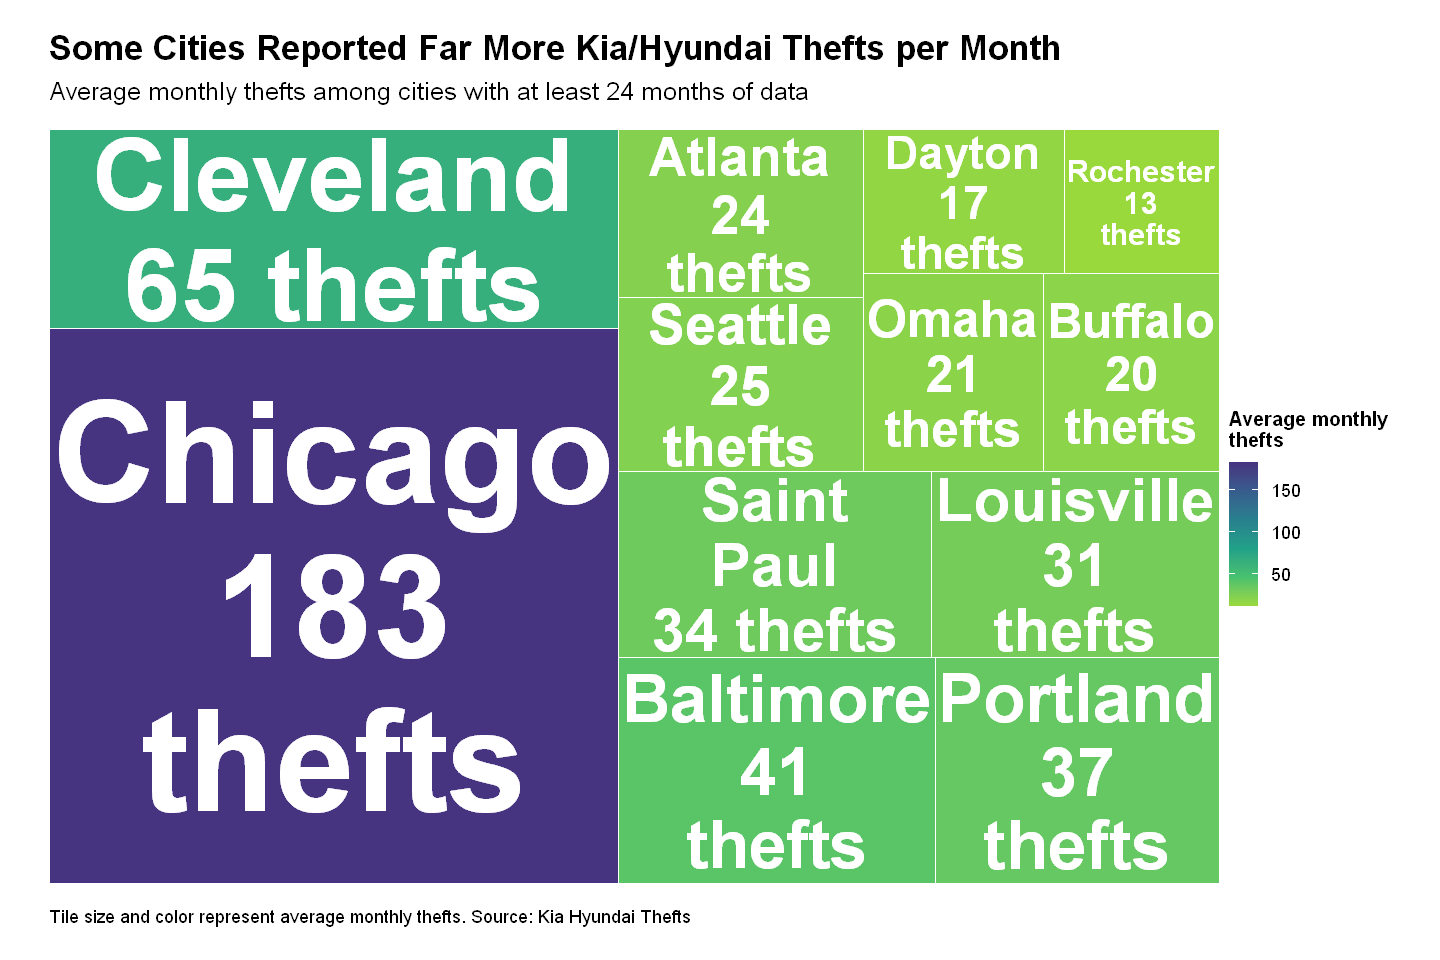

In [70]:
# Make the figure larger in Jupyter
options(repr.plot.width = 12, repr.plot.height = 8)

city_summary <- thefts %>%
  group_by(city) %>%
  summarise(
    months_reported = sum(!is.na(kia_hyundai_thefts)),
    average_monthly_thefts = mean(
      kia_hyundai_thefts,
      na.rm = TRUE
    ),
    .groups = "drop"
  ) %>%
  filter(
    months_reported >= 24,
    is.finite(average_monthly_thefts)
  ) %>%
  slice_max(
    order_by = average_monthly_thefts,
    n = 12,
    with_ties = FALSE
  )

ggplot(
  city_summary,
  aes(
    area = average_monthly_thefts,
    fill = average_monthly_thefts,
    label = paste0(
      city,
      "\n",
      round(average_monthly_thefts),
      " thefts"
    )
  )
) +
  geom_treemap(
    color = "white",
    linewidth = 2
  ) +
  geom_treemap_text(
    color = "white",
    fontface = "bold",
    place = "centre",
    reflow = TRUE,
    grow = TRUE,
    min.size = 10
  ) +
  scale_fill_viridis_c(
    option = "D",
    begin = 0.15,
    end = 0.85,
    direction = -1,
    name = "Average monthly\nthefts"
  ) +
  labs(
    title = "Some Cities Reported Far More Kia/Hyundai Thefts per Month",
    subtitle = paste(
      "Average monthly thefts among cities",
      "with at least 24 months of data"
    ),
    caption = paste(
      "Tile size and color represent average monthly thefts.",
      "Source: Kia Hyundai Thefts"
    )
  ) +
  theme_void(base_size = 16) +
  theme(
    plot.title = element_text(
      size = 21,
      face = "bold",
      margin = margin(b = 8)
    ),
    plot.subtitle = element_text(
      size = 15,
      margin = margin(b = 15)
    ),
    plot.caption = element_text(
      size = 11,
      hjust = 0,
      margin = margin(t = 15)
    ),
    legend.title = element_text(
      size = 12,
      face = "bold"
    ),
    legend.text = element_text(size = 11),
    plot.margin = margin(20, 30, 20, 30)
  )

### Visual 4 — Donut chart

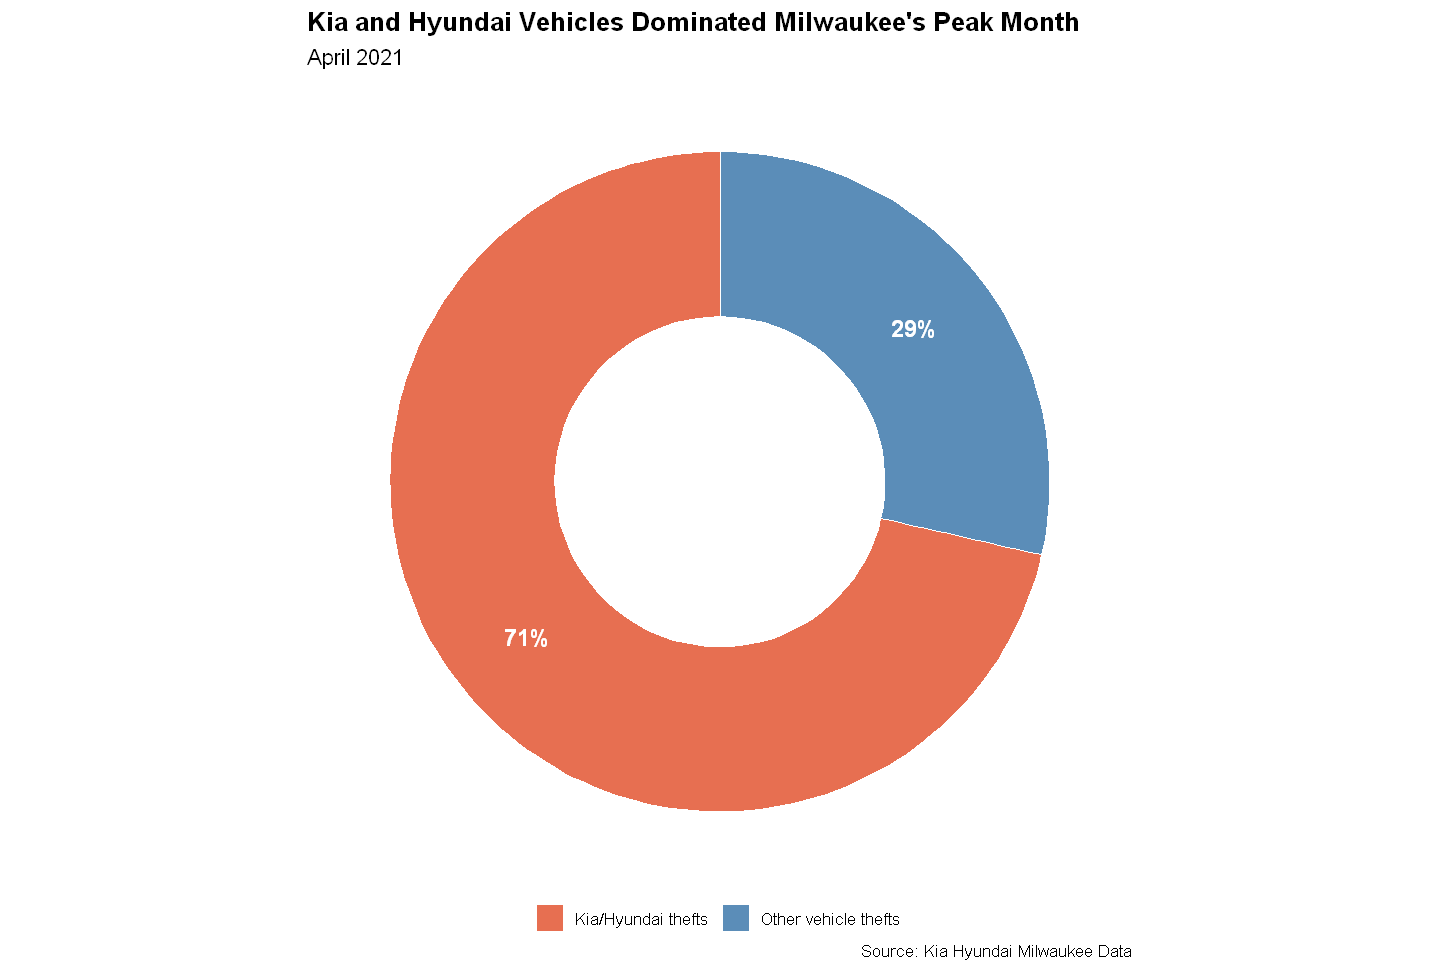

In [71]:
milwaukee_peak <- milwaukee %>%
  filter(!is.na(calculated_share)) %>%
  slice_max(
    order_by = calculated_share,
    n = 1,
    with_ties = FALSE
  )

donut_data <- tibble(
  theft_type = c("Kia/Hyundai thefts", "Other vehicle thefts"),
  thefts = c(
    milwaukee_peak$kia_hyundai_thefts,
    milwaukee_peak$other_thefts
  )
) %>%
  mutate(
    share = thefts / sum(thefts),
    label = scales::percent(share, accuracy = 1)
  )

ggplot(
  donut_data,
  aes(x = 2, y = thefts, fill = theft_type)
) +
  geom_col(width = 1, color = "white") +
  coord_polar(theta = "y") +
  xlim(0.5, 2.5) +
  geom_text(
    aes(label = label),
    position = position_stack(vjust = 0.5),
    color = "white",
    fontface = "bold",
    size = 5
  ) +
  scale_fill_manual(
    values = c(
      "Kia/Hyundai thefts" = "#E76F51",
      "Other vehicle thefts" = "#5B8DB8"
    )
  ) +
  labs(
    title = "Kia and Hyundai Vehicles Dominated Milwaukee's Peak Month",
    subtitle = format(milwaukee_peak$date, "%B %Y"),
    fill = NULL,
    caption = "Source: Kia Hyundai Milwaukee Data"
  ) +
  theme_void(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold")
  )

### Visual 5 — Area chart

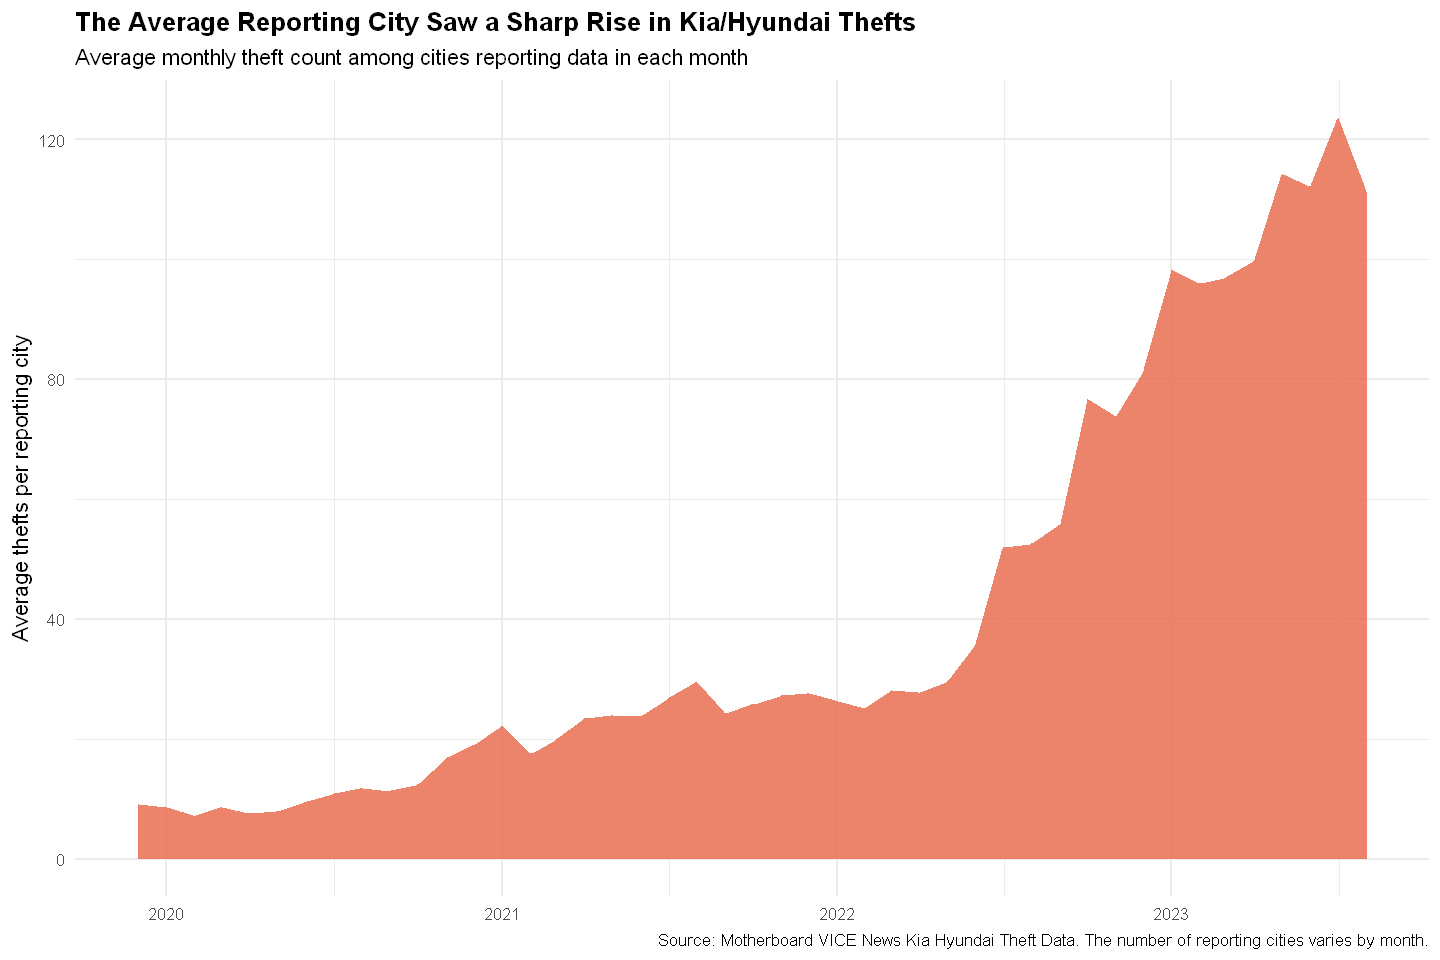

In [72]:
vice_monthly <- vice_clean %>%
  group_by(date) %>%
  summarise(
    average_thefts_per_city = mean(
      kia_hyundai_thefts,
      na.rm = TRUE
    ),
    cities_reporting = sum(!is.na(kia_hyundai_thefts)),
    .groups = "drop"
  ) %>%
  filter(
    cities_reporting > 0,
    is.finite(average_thefts_per_city)
  )

ggplot(
  vice_monthly,
  aes(x = date, y = average_thefts_per_city)
) +
  geom_area(fill = "#E76F51", alpha = 0.85) +
  labs(
    title = "The Average Reporting City Saw a Sharp Rise in Kia/Hyundai Thefts",
    subtitle = "Average monthly theft count among cities reporting data in each month",
    x = NULL,
    y = "Average thefts per reporting city",
    caption = "Source: Motherboard VICE News Kia Hyundai Theft Data. The number of reporting cities varies by month."
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold")
  )

### Visual 6 — Pie chart

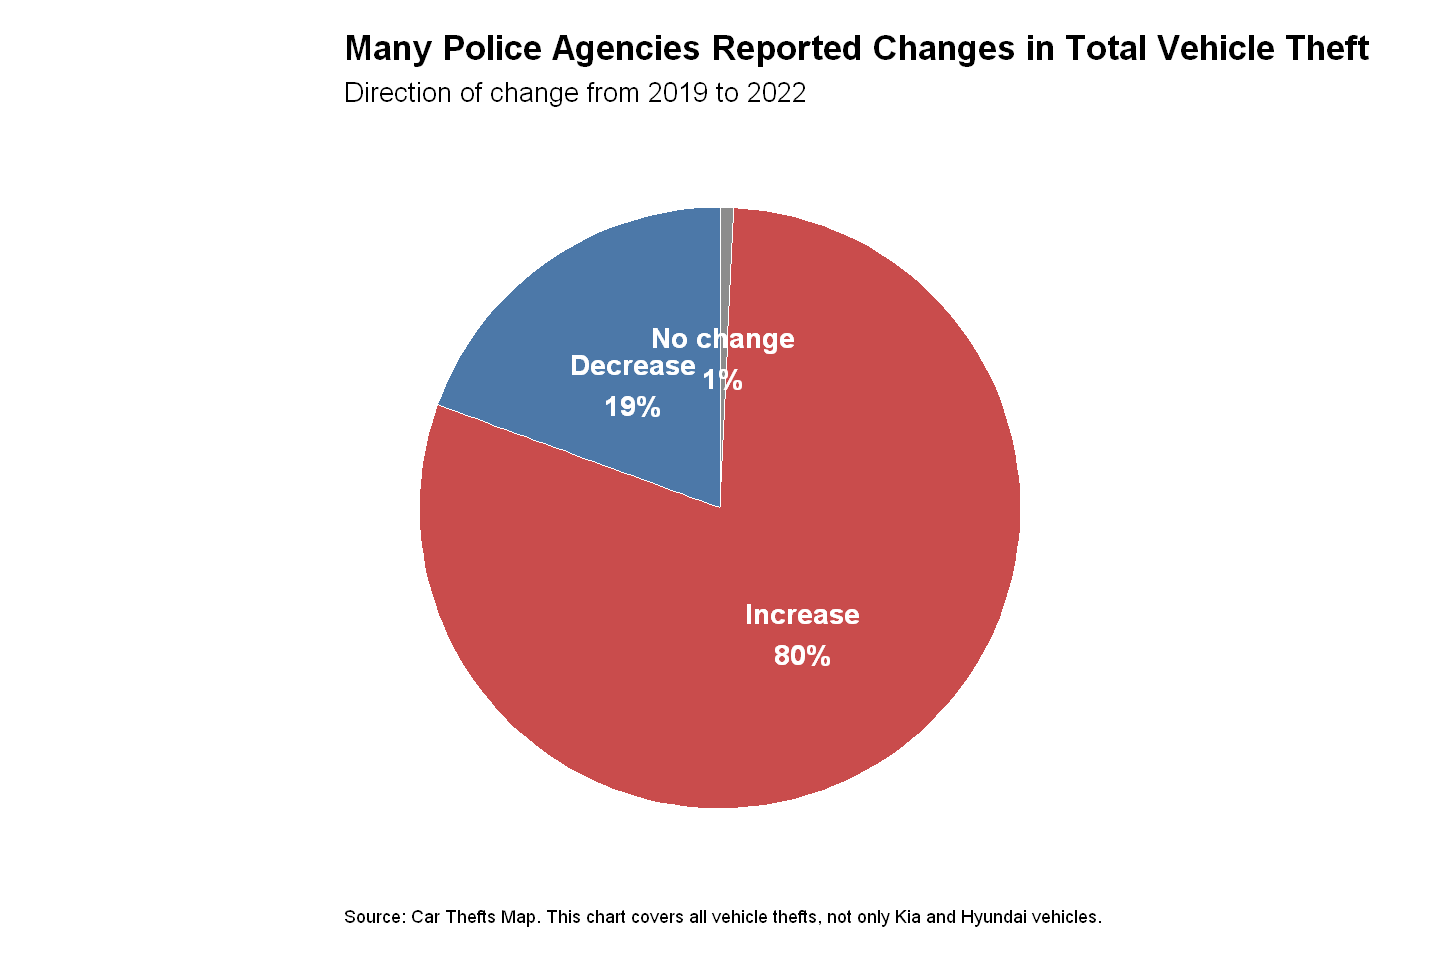

In [73]:
options(repr.plot.width = 12, repr.plot.height = 8)


# Make the plot larger in a Jupyter notebook
options(repr.plot.width = 12, repr.plot.height = 8)

agency_change <- car_map %>%
  filter(
    !is.na(thefts_2019),
    !is.na(thefts_2022)
  ) %>%
  mutate(
    change_direction = case_when(
      thefts_2022 > thefts_2019 ~ "Increase",
      thefts_2022 < thefts_2019 ~ "Decrease",
      TRUE ~ "No change"
    )
  ) %>%
  count(change_direction) %>%
  mutate(
    share = n / sum(n),
    label = paste0(
      change_direction,
      "\n",
      scales::percent(share, accuracy = 1)
    )
  )

ggplot(
  agency_change,
  aes(x = "", y = n, fill = change_direction)
) +
  geom_col(
    width = 1,
    color = "white"
  ) +
  coord_polar(theta = "y") +
  geom_text(
    aes(label = label),
    position = position_stack(vjust = 0.5),
    color = "white",
    fontface = "bold",
    size = 6
  ) +
  scale_fill_manual(
    values = c(
      "Increase" = "#C94C4C",
      "Decrease" = "#4C78A8",
      "No change" = "#8C8C8C"
    )
  ) +
  labs(
    title = "Many Police Agencies Reported Changes in Total Vehicle Theft",
    subtitle = "Direction of change from 2019 to 2022",
    caption = paste(
      "Source: Car Thefts Map.",
      "This chart covers all vehicle thefts, not only Kia and Hyundai vehicles."
    )
  ) +
  theme_void(base_size = 17) +
  theme(
    legend.position = "none",

    plot.title = element_text(
      size = 21,
      face = "bold",
      margin = margin(b = 8)
    ),

    plot.subtitle = element_text(
      size = 16,
      margin = margin(b = 15)
    ),

    plot.caption = element_text(
      size = 11,
      hjust = 0,
      margin = margin(t = 15)
    ),

    plot.margin = margin(
      t = 20,
      r = 30,
      b = 20,
      l = 30
    )
  )

## Summary

This analysis shows that Kia and Hyundai thefts became a serious and widespread vehicle-theft problem, especially after 2020. Milwaukee experienced a sharp increase, and Kia and Hyundai vehicles accounted for approximately 71% of all vehicle thefts during the peak month of April 2021.

The problem was not equally distributed across cities. Among cities with at least 24 months of reported data, Chicago had the highest average at approximately 183 Kia and Hyundai thefts per month. Cleveland, Baltimore, Portland, Saint Paul, and Louisville also reported comparatively high monthly averages.

The Motherboard VICE data show that the average number of Kia and Hyundai thefts per reporting city increased rapidly from 2020 through 2023. However, the number of cities reporting data changed between months, so the trend should be interpreted carefully.

The police-agency data also indicate that the broader vehicle-theft problem increased across much of the country. Approximately 80% of the agencies included in the analysis reported more vehicle thefts in 2022 than in 2019, while 19% reported a decrease and 1% reported no change.

Overall, the findings show that Kia and Hyundai thefts contributed substantially to the growth in vehicle theft, but the severity of the problem differed by city and reporting agency. These results describe reported trends and do not prove what caused the increases. :contentReference[oaicite:0]{index=0}

## Call to Action

Vehicle owners should contact their dealership to determine whether their vehicle qualifies for an anti-theft software update or other security improvement. Owners should also use visible physical deterrents, lock their vehicles, avoid leaving keys or valuables inside, park in well-lit areas, and report suspicious activity or theft promptly.

Dealerships and vehicle manufacturers should communicate available security upgrades clearly and make them easy for affected owners to receive.

City leaders and law-enforcement agencies should use local theft patterns to identify high-risk locations and time periods. Prevention efforts may include targeted public education, distribution of steering-wheel locks, focused patrols, and partnerships with dealerships and community organizations. Agencies should also improve consistent monthly reporting so that future prevention decisions are based on complete and reliable data.